# Part III: Downstream representation Analysis

The two LSTMs (**Word2Vec LSTM** and **GloVe LSTM**) trained in Part II are frozen and used as feature extractors for positive/negative movie review classification. Each representation goes into the same logistic regression classifier (with C tuned on validation).

**Data:** IMDB Large Movie Review Dataset (Maas et al., 2011), https://ai.stanford.edu/~amaas/data/sentiment/. We use a balanced and seeded subset: 5,000 train, 1,000 validation, and 5,000 test reviews.

**How to run:** run Parts I and II first (the models are loaded from `results/models/`). Results are written to `results/part3/`.

## 0. Setup

Import libraries and check hardware details. Part III helpers are in `src/representations.py`.

In [1]:
import sys
from pathlib import Path
import json
from collections import Counter

sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import torch
import matplotlib.pyplot as plt

from src.data import load_corpus, tokenize, unk_rate
from src.models import RecurrentLM
from src.evaluate import (
    SEED, RESULTS_DIR, Timer, perplexity, neural_mean_nll,
    save_results, hardware_summary, set_seed,
)
from src.representations import (
    IMDB_URL, SUBSET_SIZES, LABEL_NAMES, C_GRID, load_imdb_subset, encode_reviews,
    load_lstm, extract_features, bag_of_words, train_classifier, evaluate_classifier,
)

set_seed(SEED)
hardware_summary()

{'platform': 'Windows-11-10.0.26200-SP0',
 'processor': 'Intel64 Family 6 Model 170 Stepping 4, GenuineIntel',
 'python': '3.13.9',
 'torch': '2.14.1+cpu',
 'torch_threads': 16,
 'device': 'cpu'}

## 1. Data

Load the Dickens vocabulary from Part I and the IMDB subset. Reviews are tokenized with the same tokenizer and encoded with the same vocabulary as the language models, so any word outside the 4,103 Dickens vocabulary words becomes `<unk>`.

In [2]:
vocab, lm_splits = load_corpus()

with Timer() as data_timer:
    imdb = load_imdb_subset()
print(f"Loaded IMDB subset in {data_timer.seconds:.1f} s (source: {IMDB_URL})\n")

encoded = {split: encode_reviews(imdb[split]["texts"], vocab) for split in imdb}
labels = {split: np.array(imdb[split]["labels"]) for split in imdb}

print(f"{'split':<6} | {'reviews':>7} | {'positive':>8} | {'mean tokens':>11} | {'max tokens':>10} | {'<unk> rate':>10}")
for split in ["train", "valid", "test"]:
    lengths = [len(ids) for ids in encoded[split]]
    all_ids = [index for ids in encoded[split] for index in ids]
    print(f"{split:<6} | {len(lengths):>7,} | {labels[split].mean():>8.1%} | {np.mean(lengths):>11.0f} | "
          f"{max(lengths):>10,} | {unk_rate(all_ids, vocab):>10.1%}")

Loaded IMDB subset in 0.0 s (source: https://ai.stanford.edu/~amaas/data/sentiment/aclImdb_v1.tar.gz)



split  | reviews | positive | mean tokens | max tokens | <unk> rate


train  |   5,000 |    50.0% |         265 |      1,856 |      20.8%
valid  |   1,000 |    50.0% |         263 |      1,523 |      20.6%
test   |   5,000 |    50.0% |         260 |      2,386 |      20.7%


**Vocabulary mismatch:** the most frequent IMDB words that are not in the Dickens vocabulary, and one example review as the model sees it.

In [3]:
unknown = Counter(token for text in imdb["train"]["texts"] for token in tokenize(text) if token not in vocab)
print("Most frequent words mapped to <unk>:")
print(", ".join(word for word, _ in unknown.most_common(30)))

example = 0
print(f"\nExample ({LABEL_NAMES[labels['train'][example]]}):")
print(" ", imdb["train"]["texts"][example][:300])
print("As encoded:")
print(" ", " ".join(vocab.decode(encoded["train"][example][:60])))

Most frequent words mapped to <unk>:
movie, film, movies, characters, films, acting, plot, scenes, actors, director, funny, s, original, guy, role, comedy, script, tv, fun, anyone, screen, ending, actor, plays, dvd, effects, maybe, main, someone, takes

Example (positive):
  I have always been a fan of David Lynch and with this film Lynch proved to critics that he has the talent, style, and artistic integrity to make films outside of the surreal aura that he's become known for in the past decade. As much as the film is G-rated, it's pure Lynch in style, pacing, and tone
As encoded:
  i have always been a <unk> of <unk> <unk> and with this <unk> <unk> proved to <unk> that he has the <unk> , style , and <unk> <unk> to make <unk> outside of the <unk> <unk> that he 's become known for in the past <unk> . as much as the <unk> is <unk> <unk> , it 's <unk> <unk>


## 2. Frozen language models

Rebuild each LSTM with the Part I config and load its Part II weights. As a check that loading worked, the Dickens test perplexity is recomputed and compared with Part II. The untrained control has the same architecture and seed but no language-model training.

In [4]:
part1_lstm = json.loads((RESULTS_DIR / "part1" / "lstm.json").read_text(encoding="utf-8"))
RECURRENT_CONFIG = part1_lstm["config"]
LM_NAMES = ["lstm_word2vec", "lstm_glove"]
lm_results = {name: json.loads((RESULTS_DIR / "part2" / f"{name}.json").read_text(encoding="utf-8"))
              for name in LM_NAMES}

models = {name: load_lstm(RESULTS_DIR / "models" / f"{name}.pt", RecurrentLM, len(vocab), RECURRENT_CONFIG)
          for name in LM_NAMES}

set_seed(SEED)
models["lstm_untrained"] = RecurrentLM(len(vocab), cell="lstm", **RECURRENT_CONFIG).eval()

for name in LM_NAMES:
    recomputed = perplexity(neural_mean_nll(models[name], lm_splits["test"]))
    print(f"{name}: Dickens test perplexity {recomputed:.2f} (Part II: {lm_results[name]['test_perplexity']:.2f})")

lstm_word2vec: Dickens test perplexity 73.38 (Part II: 73.38)


lstm_glove: Dickens test perplexity 77.75 (Part II: 77.75)


## 3. Fixed-length representations

Each review is read by the frozen LSTM, which gives a 256-d hidden state per token. There are two ways to turn these into one 256-d vector per review:

- **mean:** average of the hidden states over the real tokens (padding excluded)
- **final:** the hidden state at the last token (`<eos>`), after the LSTM has read the whole review.

The time is the feature-extraction cost per model.

In [5]:
total_tokens = sum(len(ids) for split in encoded.values() for ids in split)
features, extract_seconds = {}, {}
for name, model in models.items():
    with Timer() as timer:
        features[name] = {split: extract_features(model, encoded[split]) for split in encoded}
    extract_seconds[name] = timer.seconds
    print(f"{name:<15}: {timer.seconds:.1f} s for {total_tokens:,} tokens "
          f"({total_tokens / timer.seconds:,.0f} tokens/s)")

lstm_word2vec  : 21.8 s for 2,889,653 tokens (132,613 tokens/s)


lstm_glove     : 19.5 s for 2,889,653 tokens (148,252 tokens/s)


lstm_untrained : 28.7 s for 2,889,653 tokens (100,745 tokens/s)


## 4. Classification

**What is compared:** the main experiment is 2 language models (Word2Vec LSTM, GloVe LSTM) × 2 pooling methods (mean, final) = 4 representations. Three reference rows help interpret them:
- **untrained LSTM** (mean and final): same architecture and seed, but never trained. Did language-model training actually help?
- **bag-of-words:** only which vocabulary words appear, with no language model. Do the LSTM features beat a simple word list?

Representation goes through the same steps. (1) Rescale each feature using the training set. (2) Train a logistic regression for each regularisation strength C in {0.001, 0.01, 0.1, 1, 10}. (3) Keep the C with the best validation accuracy. (4) Score the test set once. 

In [6]:
REPRESENTATIONS = {
    "w2v_mean": ("lstm_word2vec", "mean", "Word2Vec LSTM, mean"),
    "w2v_final": ("lstm_word2vec", "final", "Word2Vec LSTM, final"),
    "glove_mean": ("lstm_glove", "mean", "GloVe LSTM, mean"),
    "glove_final": ("lstm_glove", "final", "GloVe LSTM, final"),
    "untrained_mean": ("lstm_untrained", "mean", "untrained LSTM, mean (control)"),
    "untrained_final": ("lstm_untrained", "final", "untrained LSTM, final (control)"),
}

results = {}
for key, (model_name, pooling, label) in REPRESENTATIONS.items():
    X = {split: features[model_name][split][pooling] for split in encoded}
    classifier, best_c, valid_scores = train_classifier(X["train"], labels["train"], X["valid"], labels["valid"])
    results[key] = {"label": label, "best_C": best_c, "valid_accuracy_by_C": valid_scores,
                    "valid_accuracy": valid_scores[best_c],
                    "test": evaluate_classifier(classifier, X["test"], labels["test"])}

bow = {split: bag_of_words(encoded[split], len(vocab)) for split in encoded}
classifier, best_c, valid_scores = train_classifier(bow["train"], labels["train"], bow["valid"], labels["valid"],
                                                    scale=False)
results["bow"] = {"label": "bag-of-words, same vocabulary (reference)", "best_C": best_c,
                  "valid_accuracy_by_C": valid_scores, "valid_accuracy": valid_scores[best_c],
                  "test": evaluate_classifier(classifier, bow["test"], labels["test"])}

print(f"{'representation':<34} | {'best C':>6} | {'valid acc':>9} | {'test acc':>8} | {'test macro-F1':>13}")
for key, r in results.items():
    print(f"{r['label']:<34} | {r['best_C']:>6} | {r['valid_accuracy']:>9.1%} | "
          f"{r['test']['accuracy']:>8.1%} | {r['test']['macro_f1']:>13.3f}")

representation                     | best C | valid acc | test acc | test macro-F1
Word2Vec LSTM, mean                |    0.1 |     73.2% |    71.8% |         0.718
Word2Vec LSTM, final               |   0.01 |     56.0% |    55.1% |         0.551
GloVe LSTM, mean                   |    0.1 |     76.8% |    76.3% |         0.763
GloVe LSTM, final                  |    0.1 |     57.5% |    56.3% |         0.563
untrained LSTM, mean (control)     |   10.0 |     74.9% |    73.9% |         0.739
untrained LSTM, final (control)    |    1.0 |     57.9% |    59.2% |         0.592
bag-of-words, same vocabulary (reference) |   0.01 |     83.8% |    82.1% |         0.821


## 5. Language-model ranking vs downstream ranking

Does the better language model (lower Dickens test perplexity) also give better sentiment features?

In [7]:
print(f"{'language model':<15} | {'LM test ppl':>11} | {'test acc (mean)':>15} | {'test acc (final)':>16}")
for name, prefix in [("lstm_word2vec", "w2v"), ("lstm_glove", "glove")]:
    print(f"{name:<15} | {lm_results[name]['test_perplexity']:>11.2f} | "
          f"{results[prefix + '_mean']['test']['accuracy']:>15.1%} | {results[prefix + '_final']['test']['accuracy']:>16.1%}")

language model  | LM test ppl | test acc (mean) | test acc (final)
lstm_word2vec   |       73.38 |           71.8% |            55.1%
lstm_glove      |       77.75 |           76.3% |            56.3%


**Accuracy by review length:** test reviews are split into four equal-sized groups by token count. If the final hidden state forgets early parts of long reviews, its accuracy should fall more with length than mean pooling's.

representation         |    20-144 |   144-200 |   200-321 |  321-2386
Word2Vec LSTM, mean    |     70.7% |     72.7% |     71.5% |     72.3%
Word2Vec LSTM, final   |     53.5% |     55.2% |     57.1% |     54.6%
GloVe LSTM, mean       |     76.8% |     76.1% |     74.8% |     77.7%
GloVe LSTM, final      |     55.8% |     55.8% |     58.0% |     55.6%


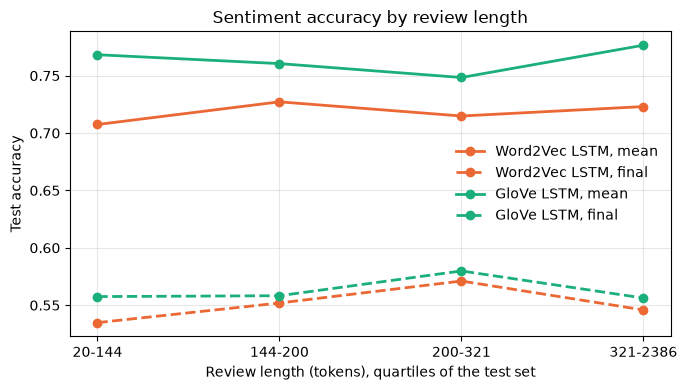

In [8]:
MAIN = ["w2v_mean", "w2v_final", "glove_mean", "glove_final"]
STYLES = {"w2v_mean": ("#eb6834", "-"), "w2v_final": ("#eb6834", "--"),
          "glove_mean": ("#1baf7a", "-"), "glove_final": ("#1baf7a", "--")}

test_lengths = np.array([len(ids) for ids in encoded["test"]])
edges = np.quantile(test_lengths, [0, 0.25, 0.5, 0.75, 1.0]).astype(int)
group = np.digitize(test_lengths, edges[1:-1])
group_names = [f"{edges[i]}-{edges[i + 1]}" for i in range(4)]

accuracy_by_length = {}
for key in MAIN:
    correct = np.array(results[key]["test"]["predictions"]) == labels["test"]
    accuracy_by_length[key] = [float(correct[group == g].mean()) for g in range(4)]

print(f"{'representation':<22} | " + " | ".join(f"{name:>9}" for name in group_names))
for key in MAIN:
    print(f"{results[key]['label']:<22} | " + " | ".join(f"{acc:>9.1%}" for acc in accuracy_by_length[key]))

fig, ax = plt.subplots(figsize=(7, 4))
for key in MAIN:
    color, linestyle = STYLES[key]
    ax.plot(range(4), accuracy_by_length[key], marker="o", color=color, linestyle=linestyle,
            linewidth=2, label=results[key]["label"])
ax.set_xticks(range(4), group_names)
ax.set_xlabel("Review length (tokens), quartiles of the test set")
ax.set_ylabel("Test accuracy")
ax.set_title("Sentiment accuracy by review length")
ax.legend(frameon=False)
ax.grid(alpha=0.3)
fig.tight_layout()
(RESULTS_DIR / "part3").mkdir(parents=True, exist_ok=True)
fig.savefig(RESULTS_DIR / "part3" / "accuracy_by_length.png", dpi=200, bbox_inches="tight")
plt.show()

## 6. Error analysis

Among the four LSTM representations, the one with the best **validation** accuracy is GloVe LSTM with mean pooling. We further explore its confusion matrix, the share of `<unk>` in correctly vs wrongly classified reviews, and its most confident mistakes.

In [9]:
best_key = max(MAIN, key=lambda key: results[key]["valid_accuracy"])
best = results[best_key]["test"]
predictions = np.array(best["predictions"])
prob_positive = np.array(best["prob_positive"])
test_unk = np.array([unk_rate(ids, vocab) for ids in encoded["test"]])
wrong = np.where(predictions != labels["test"])[0]

print(f"Best on validation: {results[best_key]['label']}")
print("Confusion matrix (rows = true, columns = predicted; negative, positive):")
print(np.array(best["confusion_matrix"]))
print(f"\nMean <unk> rate: correct {test_unk[predictions == labels['test']].mean():.1%}, "
      f"wrong {test_unk[wrong].mean():.1%}")

def show_review(index):
    ids = encoded["test"][index]
    text = imdb["test"]["texts"][index]
    print(f"true {LABEL_NAMES[labels['test'][index]]}, P(positive) = {prob_positive[index]:.2f}, "
          f"{len(ids)} tokens, <unk> {test_unk[index]:.0%}")
    print(f"  {text[:400]}{'...' if len(text) > 400 else ''}\n")

false_positives = wrong[labels["test"][wrong] == 0]
false_negatives = wrong[labels["test"][wrong] == 1]
print("\nMost confident false positives (negative reviews predicted positive):\n")
for index in false_positives[np.argsort(-prob_positive[false_positives])][:3]:
    show_review(index)
print("Most confident false negatives (positive reviews predicted negative):\n")
for index in false_negatives[np.argsort(prob_positive[false_negatives])][:3]:
    show_review(index)

Best on validation: GloVe LSTM, mean
Confusion matrix (rows = true, columns = predicted; negative, positive):
[[1913  587]
 [ 596 1904]]

Mean <unk> rate: correct 20.2%, wrong 20.5%

Most confident false positives (negative reviews predicted positive):

true negative, P(positive) = 0.99, 53 tokens, <unk> 17%
  I didn't hate this movie as much as some on my all time black list, but I consider it a total wast of film. Jeremy Irons, Iron Jeremy, Ron Jeremy. Think about it. Scene one is very good, all the rest are crap.

true negative, P(positive) = 0.99, 85 tokens, <unk> 27%
  This film has the language, the style and the attitude down ... plus greats rides from Occy (a world champ) and the great Jerry Lopez. John Philbin as Turtle has the surf pidgin down, and the surfing scenes are still the best ever. A true classic that can be seen many times. Nia Peeples is a babe, and Laird Hamilton shows the early stuff that has made him the world's number one extreme surfer.

true negative, P(posi

**Where the two language models disagree** (mean pooling): how often each is right when the other is wrong, with one example each way.

In [10]:
w2v_right = np.array(results["w2v_mean"]["test"]["predictions"]) == labels["test"]
glove_right = np.array(results["glove_mean"]["test"]["predictions"]) == labels["test"]
print(f"Both right: {np.mean(w2v_right & glove_right):.1%}   Both wrong: {np.mean(~w2v_right & ~glove_right):.1%}")
print(f"Only Word2Vec right: {np.mean(w2v_right & ~glove_right):.1%}   Only GloVe right: {np.mean(~w2v_right & glove_right):.1%}\n")

for title, mask in [("Word2Vec right, GloVe wrong", w2v_right & ~glove_right),
                    ("GloVe right, Word2Vec wrong", ~w2v_right & glove_right)]:
    index = np.where(mask)[0][0]
    text = imdb["test"]["texts"][index]
    print(f"{title} (true {LABEL_NAMES[labels['test'][index]]}, {len(encoded['test'][index])} tokens):")
    print(f"  {text[:400]}{'...' if len(text) > 400 else ''}\n")

Both right: 62.1%   Both wrong: 13.9%
Only Word2Vec right: 9.7%   Only GloVe right: 14.2%

Word2Vec right, GloVe wrong (true negative, 672 tokens):
  Director/screenwriter Diane English's 2008 update of George Cukor's 1939 MGM classic comedy unfortunately shows more mothballs than its predecessor. Based on Clare Booth Luce's shrewdly observant 1936 play on the relationships that evolve among a strictly female group of pampered Manhattan socialites, the story would seem ripe for a contemporary remake. Instead, because of English's thematic overr...

GloVe right, Word2Vec wrong (true negative, 250 tokens):
  That's the only word I can think of to describe this movie. Not waste as in a waste of time (any time spent with these characters is never wasted), but waste as in a waste of opportunities.  When I see this movie, I think of all the Star Trek novels that were written which would have made a much better film than the story Shatner chose. The setup was like an average television episod

**Save:** all scores, chosen C values, predictions, the length analysis and the subset review ids to `results/part3/classification.json`.

In [11]:
path = save_results("part3/classification", {
    "dataset": {"name": "IMDB Large Movie Review Dataset (Maas et al., 2011)", "url": IMDB_URL,
                "subset_sizes": SUBSET_SIZES, "seed": SEED,
                "review_ids": {split: imdb[split]["ids"] for split in imdb},
                "unk_rate": {split: unk_rate([i for ids in encoded[split] for i in ids], vocab) for split in encoded}},
    "classifier": {"model": "logistic regression (standardised features; bag-of-words unscaled)",
                   "C_grid": C_GRID, "selection": "best validation accuracy"},
    "feature_extraction_seconds": extract_seconds,
    "results": results,
    "accuracy_by_length": {"groups": group_names, "accuracy": accuracy_by_length},
    "hardware": hardware_summary(),
})
print(f"Saved to {path}")

Saved to C:\Users\ohrac\Documents\Y4\DSA4213\DSA4213 Assignment\results\part3\classification.json
